# NASA cloud history and deployment status
Real observations and a real GEOS sample are inspected here. No operational model is fitted or approved.

In [1]:
from pathlib import Path
import json
import pandas as pd
from firecast.clouds import acquire_clouds, attach_cloud_context
root=Path.cwd() if (Path.cwd()/'configs').exists() else Path.cwd().parent
report=acquire_clouds(root/'configs/cloud-acquisition.json',root/'data/nasa-clouds')
context=attach_cloud_context(root/'data/nasa-lebanon/weather_historical.csv',root/'data/nasa-clouds/cloud_history.csv.gz',root/'data/nasa-clouds/weather_cloud_context.csv.gz')
{'cloud_point_days':report['point_days'],'weather_cloud_rows':len(context),'coverage_evidence_qualified':report['coverage_evidence_qualified'],'failures':report['failures']}

{'cloud_point_days': 20456,
 'weather_cloud_rows': 61368,
 'coverage_evidence_qualified': False,
 'failures': []}

Text(0, 0.5, 'Daily cloud amount (%)')

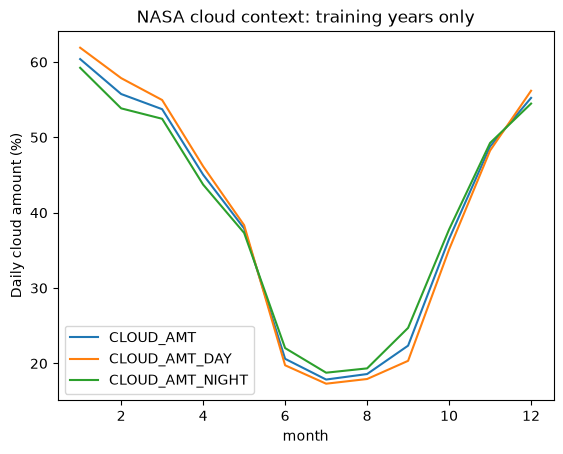

In [2]:
clouds=pd.read_csv(root/'data/nasa-clouds/cloud_history.csv.gz')
training=clouds[clouds.date<'2021-01-01'].copy()
training['month']=pd.to_datetime(training.date).dt.month
ax=training.groupby('month')[['CLOUD_AMT','CLOUD_AMT_DAY','CLOUD_AMT_NIGHT']].mean().plot(title='NASA cloud context: training years only')
ax.set_ylabel('Daily cloud amount (%)')

In [3]:
from firecast.geos import decode_hour
file=next((root/'data/nasa-lebanon/raw/geos').glob('*.nc4'))
manifest=json.loads(file.with_suffix(file.suffix+'.manifest.json').read_text())
hour=decode_hour(file,pd.read_csv(root/'outputs/real-preparation/candidate-grid.csv'),manifest['downloaded_at'])
hour[['cell_id','issue_time','available_at','valid_start','temperature_c','humidity_pct']].head()

,cell_id,issue_time,available_at,valid_start,temperature_c,humidity_pct
0,1230_2150,2026-11-14 00:00:00+00:00,2026-11-14 15:16:14.827403+00:00,2026-11-15 00:00:00+00:00,22.744348,74.124040
1,1230_2151,2026-11-14 00:00:00+00:00,2026-11-14 15:16:14.827403+00:00,2026-11-15 00:00:00+00:00,22.744348,74.124040
2,1230_2152,2026-11-14 00:00:00+00:00,2026-11-14 15:16:14.827403+00:00,2026-11-15 00:00:00+00:00,15.338098,45.812397
3,1230_2153,2026-11-14 00:00:00+00:00,2026-11-14 15:16:14.827403+00:00,2026-11-15 00:00:00+00:00,15.338098,45.812397
4,1230_2154,2026-11-14 00:00:00+00:00,2026-11-14 15:16:14.827403+00:00,2026-11-15 00:00:00+00:00,15.338098,45.812397


In [4]:
from firecast.release import assess_release
readiness=json.loads((root/'outputs/real-preparation/readiness.json').read_text())
release=assess_release(readiness)
{'approved':release['approved'],'unmet_release_checks':release['failures']}

{'approved': False,
 'unmet_release_checks': ['real_data',
  'operational_forecast_mode',
  'compatible_observation_coverage',
  'national_vegetation_grid',
  'historical_feature_availability',
  'issued_forecast_backtest',
  'independent_incident_split_review',
  'calibration_review',
  'current_sensor_transition_review',
  'test_sample_size',
  'test_span',
  'better_pr_auc',
  'better_brier',
  'validated_domain']}

Daily SYN1DEG cloud context does not establish cloud conditions at individual fire-satellite overpasses. The decoded GEOS sample lacks a full daily sequence and precipitation. Protected masks/geolocation and environmental rasters still need authenticated acquisition. No real production model is approved. Read `decisions.md`, `docs/statecharts.md` and `docs/deployment.md`.